# TTE map: compare tree cover inputs

Runs the TTE workflow (`lib/tte_map.py`) on square sites with different 30 m tree canopy cover
(TCC) inputs and lines them up with the original circa-2010 map (GEE `TTE_DATA_v201902v2`,
Montesano et al. 2020 ERL). **One row per site; the two references on the left, then one column
per tree cover input.**

| Column | Tree cover input | Year | Coverage |
|---|---|---|---|
| Reference A: GEE script | the published GEE map (its own classes) | c. 2010 | circumpolar |
| Reference B: Python script | the TCC stored in the GEE map, classified again here: `cal_2m_tcc` in North America, Hansen 2010 in Eurasia | c. 2010 | TTE domain |
| Hansen 2010 | Hansen GFC v1.6 `treecover2000` minus 2001-2009 loss (public) | 2010 | global |
| Hansen 2025 | the latest Hansen GFC (v1.13): the same `treecover2000` minus all 2001-2025 loss (no gain); read the same way as Hansen 2010 | 2025 | global |
| ABoVE boreal TCC | Feng et al. 2022, Landsat TCC calibrated with boreal reference data (ORNL DAAC 2012) | 2010 | 47-73 N |
| ABoVE, TCC < 5 % set to 0 | the same ABoVE TCC with a 5 % zero floor (see below) | 2010 | 47-73 N |
| GFCC | Sexton et al. GFCC30TC v003 (LP DAAC) | 2010 | global |
| Massey | Massey et al. 2023 (ORNL DAAC 2296), 2008-2012 composite | 2010 | boreal North America |
| Meta CHM 2 m cover | % of ~1 m Meta/WRI canopy height (CHM v2) pixels >= 2 m (public) | recent, varies | global |

**What to expect.** In Eurasia the GEE map used Hansen 2010, so the Hansen and GEE TCC columns
should match Reference A. In North America it used `cal_2m_tcc` (Landsat TCC calibrated to 2 m
canopy cover from lidar), so every column except Reference B will differ there. Reference B is our
stand-in for `cal_2m_tcc`: the GEE map kept its input TCC in its `tcc` band, and the domain pixels
it left unclassified had TCC 0.

**Earthdata access.** ABoVE, GFCC and Massey are NASA DAAC products, read directly from their
S3 buckets with temporary credentials. These come from maap-py if your MAAP account provides them,
otherwise from your Earthdata Login through `earthaccess`. The "Earthdata login" cell below asks for
your Earthdata username and password once and saves them in `~/.netrc` (readable only by you).
Without Earthdata access those columns are left blank with the reason.

## Two references

| Column | What it is | Made by |
|---|---|---|
| **Reference A: GEE script** | the published map `TTE_DATA_v201902v2` (circa 2010), as downloaded from GEE | `TTE _map_working` in GEE (Montesano et al. 2020) |
| **Reference B: Python script** | the TCC stored in the published map (its `tcc` band: `cal_2m_tcc` in North America, Hansen 2010 in Eurasia), classified again with `lib/tte_map.py` | the Python port |

Every other column is also the **Python script** (`lib/tte_map.py`), run with a different tree cover
input. Reference B is the Python script given (nearly) the GEE script's own input, so A vs B shows
what the port itself changes; B vs the other columns shows what the tree cover input changes.

**Zero floor.** Before the TTE workflow runs, ABoVE TCC values below 5 % are set to 0. The original
map's inputs (Hansen, `cal_2m_tcc`) are exactly 0 where there are no trees, and the TTE classes rely on
those zeros (TCC 0 with no change around is left out of the map; TCC 0 next to trees is the non-forest
edge), while the ABoVE TCC has a low non-zero background almost everywhere; the floor turns that
background back into "no trees".

*Side effect:* the sparse zone is TCC above 0 and up to 5 %, so with a 5 % floor only pixels at exactly
5 % stay sparse, and the sparse classes (1-4) nearly disappear in the floored runs.

## Why the Python script can differ from the GEE script

**Order of operations is the same.** In `TTE _map_working` the TCC is masked to the TTE domain
*before* the abruptness is computed (`tcc_data = tte_domain.where(..., tcc)`), water (GSW >= 1) is then
set to TCC 0 even outside the domain, abruptness is computed, and the result is masked to the domain
again and to `mask_abrupt` (TCC >= 0 and abruptness != 0). `tte_map.classify` does the same steps.

**Reference B (Python with the GEE map's TCC):**
1. *Resampled twice.* The GEE map (polar LAEA, 30 m) was downloaded on EPSG:4326 tiles (nearest);
   the Python script resamples it back to the polar grid (nearest). Some pixels are duplicated or
   dropped, which changes the slope, so abruptness and classes change pixel by pixel. This looks like
   the main cause of the 2-8 % disagreement: the disagreeing pixels are not concentrated next to
   clipped pixels.
2. *Already clipped.* The `tcc` band exists only where the map is classified. Unclassified domain pixels
   are filled with 0, which is right for "TCC 0 with no change around" (most of them) but wrong for
   the few pixels GEE left out for other reasons (masked abruptness at the domain edge, no-data in
   `cal_2m_tcc`); those become 0 and give their neighbours an edge.

**Any Python run:**
3. *Domain.* Read from the downloaded GEE tiles (EPSG:4326) and resampled back: edges move by a pixel
   in places (0.1-0.4 % of domain pixels).
4. *Hansen and GSW reads.* GEE read them through its pyramids (2x2 blocks north of ~64.07 N) with its
   own nearest-neighbour sampling; `tte_map.py` copies the pyramids, but 1-5 % of TCC pixels still
   differ (in stripes that follow GEE's internal tiles).
5. *Masked inputs.* In GEE, `image.where(test, value)` keeps the input where `value` is masked, so
   domain pixels with no TCC (e.g. no-data in `cal_2m_tcc`) took the domain value, 1, i.e. TCC 1 %.
   The Python script leaves them as no data. Small: <= 0.5 % of classified pixels are TCC 1 in class 1.
6. *Zones 3 and 4.* GEE split TCC > 30 % by the TCC relative error (Feng et al.); there is no such layer
   here, so zone 4 becomes 3. Both are class 9, so classes are unaffected; only `tte_zones` differs.
7. *Slope at edges.* `ee.Terrain.slope` and the numpy 4-neighbour slope may treat masked neighbours
   (domain edge, no data) differently.
8. *Class thresholds.* Abruptness exactly at -0.5, 0, 0.5 or 1 can fall on either side with float rounding.
9. *The comparison itself.* Agreement is counted on the GEE download grid, so the Python map is
   resampled once more (nearest) for counting.

**Python with Hansen (column "Hansen 2010") in North America** differs most for a different reason:
GEE used `cal_2m_tcc` there, not Hansen.

## 0. Setup

In [1]:
import os, sys, warnings
if os.path.isdir('/srv/conda/envs/notebook/share/proj'):
    os.environ.setdefault('PROJ_DATA', '/srv/conda/envs/notebook/share/proj')
warnings.filterwarnings('ignore', message='.*geographic CRS.*')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.join(os.path.expanduser('~/code/tte'), 'lib'))
import tte_map as tm
import tte_tcc_sources as ts
import tte_compare as tc

### Earthdata login

Needed once per Hub home directory. If there is no `~/.netrc` (or `~/credentials.ini` with an
`[EarthData]` section), this asks for your Earthdata Login username and password and saves them
in `~/.netrc`. Then it checks that S3 credentials can be made for the ORNL and LP DAACs.

In [2]:
import earthaccess
if ts.earthdata_login() is None:
    try:
        earthaccess.login(strategy='interactive', persist=True)    # prompts; writes ~/.netrc
    except Exception as e:
        print('Earthdata login needs a prompt: run this cell in the notebook itself.', type(e).__name__)
for daac in ('ornl', 'lpdaac'):
    try:
        print(daac, 'S3 access OK' if ts.earthdata_options(daac)['scheme'] == 's3' else 'https access only')
    except Exception as e:
        print(daac, 'no access:', str(e)[:200])

ornl S3 access OK


lpdaac S3 access OK


## 1. Settings


* `SITES`: name -> (lon, lat) of the centre of a square, `SIZE_KM` on a side. Each is the most mixed
  15 km window (forest, treeline, tundra) of the reference map in its region: Alaska (3), Scandinavia (2),
  western Siberia (2), Taymyr (1) and eastern Siberia (2). Any place in the TTE domain works. Coverage notes: the ABoVE boreal TCC has no tiles north of 70 N in
  Taymyr (so none at Khatanga) or north of 67.5 N west of 162.5 W (so the Noatak site is on the
  lower river, inside its coverage); Massey is North America only.
* Results are saved per site and input in `OUT_DIR`, so a re-run only computes what is new
  (`REDO = True` recomputes).

* `SOURCES`: the tree cover inputs, in column order: a label and a function
  `(transform, shape, lon, lat) -> TCC (%)` on the 30 m polar grid. Add a column by adding an entry.

In [3]:
SITES = {                                   # name: (lon, lat) of the square's centre
    'Eastern Seward Peninsula': (-161.84, 64.85),
    'Lower Noatak River':       (-162.25, 67.19),
    'Eastern Brooks Range':     (-145.71, 67.61),
    'Northern Scandinavia':     (25.55, 69.23),     # Finnmark / Utsjoki
    'Tornetrask, N Sweden':     (20.40, 68.33),
    'Lower Ob (Salekhard)':     (67.51, 66.12),     # western Siberia
    'Pur-Taz (Urengoy)':        (77.83, 66.36),     # western Siberia
    'Khatanga':                 (102.29, 72.07),    # Taymyr
    'Lower Indigirka':          (147.55, 69.83),    # eastern Siberia
    'Lower Kolyma':             (159.68, 68.10),    # eastern Siberia
}
SIZE_KM = 15

OUT_DIR = os.path.expanduser('~/my-private-bucket/tte/compare_tcc')
REDO = False

SOURCES = {
    'gee_tcc':    dict(label='Ref. B: Python script\nwith the GEE map\'s TCC',
                       run=lambda tr, sh, lon, lat: ts.tcc_gee_tte(tr, sh, tc.gee_paths(lon, lat))),
    'hansen2010': dict(label='Hansen 2010',
                       run=lambda tr, sh, lon, lat: tm.tcc_hansen(tr, sh, year=2010)),
    'hansen2025': dict(label='Hansen 2025\n(GFC v1.13, latest)',
                       run=lambda tr, sh, lon, lat: tm.tcc_hansen(tr, sh, year=2026, version='GFC-2025-v1.13')),
    'above2010':  dict(label='ABoVE boreal TCC 2010\n(Feng et al.)',
                       run=lambda tr, sh, lon, lat: ts.tcc_above_boreal(tr, sh, year=2010)),
    'above2010_floor5': dict(label='ABoVE boreal TCC 2010\nTCC < 5 % set to 0',
                       run=lambda tr, sh, lon, lat: ts.zero_floor(ts.tcc_above_boreal(tr, sh, year=2010), 5)),
    'gfcc2010':   dict(label='GFCC30TC 2010\n(Sexton et al.)',
                       run=lambda tr, sh, lon, lat: ts.tcc_gfcc(tr, sh, year=2010)),
    'massey2010': dict(label='Massey TCC 2010\n(N. America only)',
                       run=lambda tr, sh, lon, lat: ts.tcc_massey(tr, sh, year=2010)),
    'meta_chm2m': dict(label='Meta CHM v2\n% cover >= 2 m',
                       run=lambda tr, sh, lon, lat: ts.tcc_meta_chm(tr, sh, version='v2', ht_min=2)),
}

## 2. Run the TTE workflow for every site and input

Each site is computed on the TTE map's own grid (north polar LAEA, 30 m), over the square plus a
margin so the abruptness at the edges is right. Domain and water (GSW, read as GEE did) are the
same for every column of a site, so only the tree cover changes.

In [4]:
STATUS = tc.run_sites(SITES, SOURCES, OUT_DIR, SIZE_KM, redo=REDO)

Northern Scandinavia: grid (685, 693), 100% in the TTE domain (2s)
  massey2010: no data at this site


Tornetrask, N Sweden: grid (659, 671), 97% in the TTE domain (2s)
  massey2010: no data at this site


Lower Ob (Salekhard): grid (681, 670), 90% in the TTE domain (2s)
  massey2010: no data at this site


Pur-Taz (Urengoy): grid (624, 608), 93% in the TTE domain (3s)
  massey2010: no data at this site


Khatanga: grid (622, 612), 85% in the TTE domain (3s)
  above2010: no data at this site


  above2010_floor5: no data at this site
  massey2010: no data at this site


Lower Indigirka: grid (710, 715), 87% in the TTE domain (2s)
  massey2010: no data at this site


Lower Kolyma: grid (659, 670), 96% in the TTE domain (4s)
  massey2010: no data at this site


In [5]:
COLUMNS = ['reference'] + list(SOURCES)
LABELS = {'reference': 'Ref. A: GEE script\npublished map c. 2010', **{k: v['label'] for k, v in SOURCES.items()}}
DISP = tc.load_display(SITES, SOURCES, OUT_DIR, SIZE_KM)          # equal-area squares, for maps and areas
PIX = tc.load_pixel_maps(SITES, SOURCES, OUT_DIR, SIZE_KM)        # GEE tile pixels, for agreement
AGREE = tc.agreement_table(DISP, SITES, COLUMNS, pixel_maps=PIX)

## 3. Agreement with Reference A (GEE script)

* **same class**: share of pixels with the same class, among pixels classified in both maps
* **overlap**: pixels classified in both / pixels classified in either (1 = same footprint)

These two are measured on the GEE map's own pixel grid (its EPSG:4326 download tile), so only the
Python map is resampled, once. The classes change pixel to pixel, so comparing two resampled maps
would understate agreement.
* **classified km²**, **closed %** (class 9) and **mean TCC** in the domain show whether an input
  sees more or denser forest than the reference

In [6]:
for col, fmt in [('same_class', '{:.0%}'), ('overlap', '{:.0%}'), ('classified_km2', '{:.0f}'),
                 ('closed_pct', '{:.0f}'), ('mean_tcc', '{:.1f}')]:
    t = AGREE.pivot(index='site', columns='input', values=col).reindex(index=list(SITES), columns=COLUMNS)
    display(tc.styled(t, fmt, col))

input,reference,gee_tcc,hansen2010,hansen2025,above2010,above2010_floor5,gfcc2010,massey2010,meta_chm2m
site,,,,,,,,,
Eastern Seward Peninsula,100%,92%,36%,36%,31%,31%,26%,30%,35%
Lower Noatak River,100%,93%,18%,18%,6%,7%,22%,5%,6%
Eastern Brooks Range,100%,96%,22%,22%,11%,12%,23%,14%,17%
Northern Scandinavia,100%,98%,94%,94%,25%,25%,17%,-,30%
"Tornetrask, N Sweden",100%,97%,94%,94%,20%,21%,13%,-,32%
Lower Ob (Salekhard),100%,93%,91%,91%,27%,34%,15%,-,35%
Pur-Taz (Urengoy),100%,92%,89%,89%,28%,33%,22%,-,40%
Khatanga,100%,94%,91%,91%,-,-,18%,-,14%
Lower Indigirka,100%,96%,91%,91%,15%,20%,12%,-,22%


input,reference,gee_tcc,hansen2010,hansen2025,above2010,above2010_floor5,gfcc2010,massey2010,meta_chm2m
site,,,,,,,,,
Eastern Seward Peninsula,100%,98%,84%,84%,61%,67%,61%,63%,87%
Lower Noatak River,100%,98%,71%,71%,34%,46%,35%,37%,62%
Eastern Brooks Range,100%,99%,86%,85%,77%,77%,78%,78%,77%
Northern Scandinavia,100%,100%,99%,99%,73%,73%,76%,-,76%
"Tornetrask, N Sweden",100%,99%,99%,99%,77%,77%,78%,-,40%
Lower Ob (Salekhard),100%,97%,96%,96%,73%,76%,75%,-,59%
Pur-Taz (Urengoy),100%,96%,95%,95%,73%,73%,81%,-,62%
Khatanga,100%,97%,95%,95%,-,-,58%,-,63%
Lower Indigirka,100%,99%,98%,98%,73%,75%,79%,-,76%


input,reference,gee_tcc,hansen2010,hansen2025,above2010,above2010_floor5,gfcc2010,massey2010,meta_chm2m
site,,,,,,,,,
Eastern Seward Peninsula,125,123,126,126,202,185,202,198,122
Lower Noatak River,72,72,75,75,212,155,207,197,113
Eastern Brooks Range,172,171,170,168,220,220,219,220,176
Northern Scandinavia,170,170,170,170,215,214,222,-,205
"Tornetrask, N Sweden",171,170,170,170,213,211,215,-,72
Lower Ob (Salekhard),152,149,149,149,193,174,199,-,106
Pur-Taz (Urengoy),170,166,168,168,183,173,202,-,132
Khatanga,131,128,131,131,-,-,108,-,136
Lower Indigirka,148,147,148,148,183,167,171,-,180


input,reference,gee_tcc,hansen2010,hansen2025,above2010,above2010_floor5,gfcc2010,massey2010,meta_chm2m
site,,,,,,,,,
Eastern Seward Peninsula,28,30,70,70,50,55,18,56,72
Lower Noatak River,0,0,30,30,16,21,1,30,47
Eastern Brooks Range,7,8,38,37,42,42,14,45,46
Northern Scandinavia,26,26,26,26,24,24,5,-,39
"Tornetrask, N Sweden",25,25,25,25,9,9,1,-,30
Lower Ob (Salekhard),25,25,25,25,12,13,2,-,28
Pur-Taz (Urengoy),26,25,25,25,14,15,8,-,38
Khatanga,9,8,9,9,-,-,0,-,46
Lower Indigirka,19,19,19,19,0,0,0,-,25


input,reference,gee_tcc,hansen2010,hansen2025,above2010,above2010_floor5,gfcc2010,massey2010,meta_chm2m
site,,,,,,,,,
Eastern Seward Peninsula,13.4,13.4,30.1,30.1,29.2,28.8,15.5,44.6,33.5
Lower Noatak River,2.3,2.3,7.3,7.3,13.6,12.7,6.2,22.1,18.2
Eastern Brooks Range,8.6,8.6,19.4,18.9,28.9,28.9,13.3,32.3,31.5
Northern Scandinavia,13.5,13.5,13.6,13.6,22.8,22.8,13.3,-,26.7
"Tornetrask, N Sweden",14.9,14.9,15.1,15.1,16.6,16.5,7.4,-,8.2
Lower Ob (Salekhard),13.3,13.4,14.0,14.0,14.8,14.2,10.1,-,10.7
Pur-Taz (Urengoy),15.0,15.0,17.2,17.1,15.9,15.4,7.7,-,20.7
Khatanga,6.7,6.7,8.4,8.4,-,-,0.4,-,25.5
Lower Indigirka,10.8,10.8,11.5,11.5,9.1,8.5,2.1,-,20.6


## 4. Matrix: TTE classes

GEE class palette (`tte_class_pal`); domain pixels that are not classified are the GEE domain gray.
The two numbers in the lower left of each map compare that map with Reference A (the GEE map),
counted on the GEE map's own pixel grid:
* **same class**: of the pixels that both maps classify, the share that gets the same TTE class. It asks:
  where both maps see a forest structure pattern, is it the same pattern?
* **overlap**: pixels classified in both maps / pixels classified in either map. It asks: do the two maps
  classify the same places? 100 % = exactly the same footprint; it drops when one map classifies areas the
  other leaves out (e.g. tundra that the GEE map leaves unclassified).

A map can have a high overlap and a low same class (same places, different patterns), or the reverse.

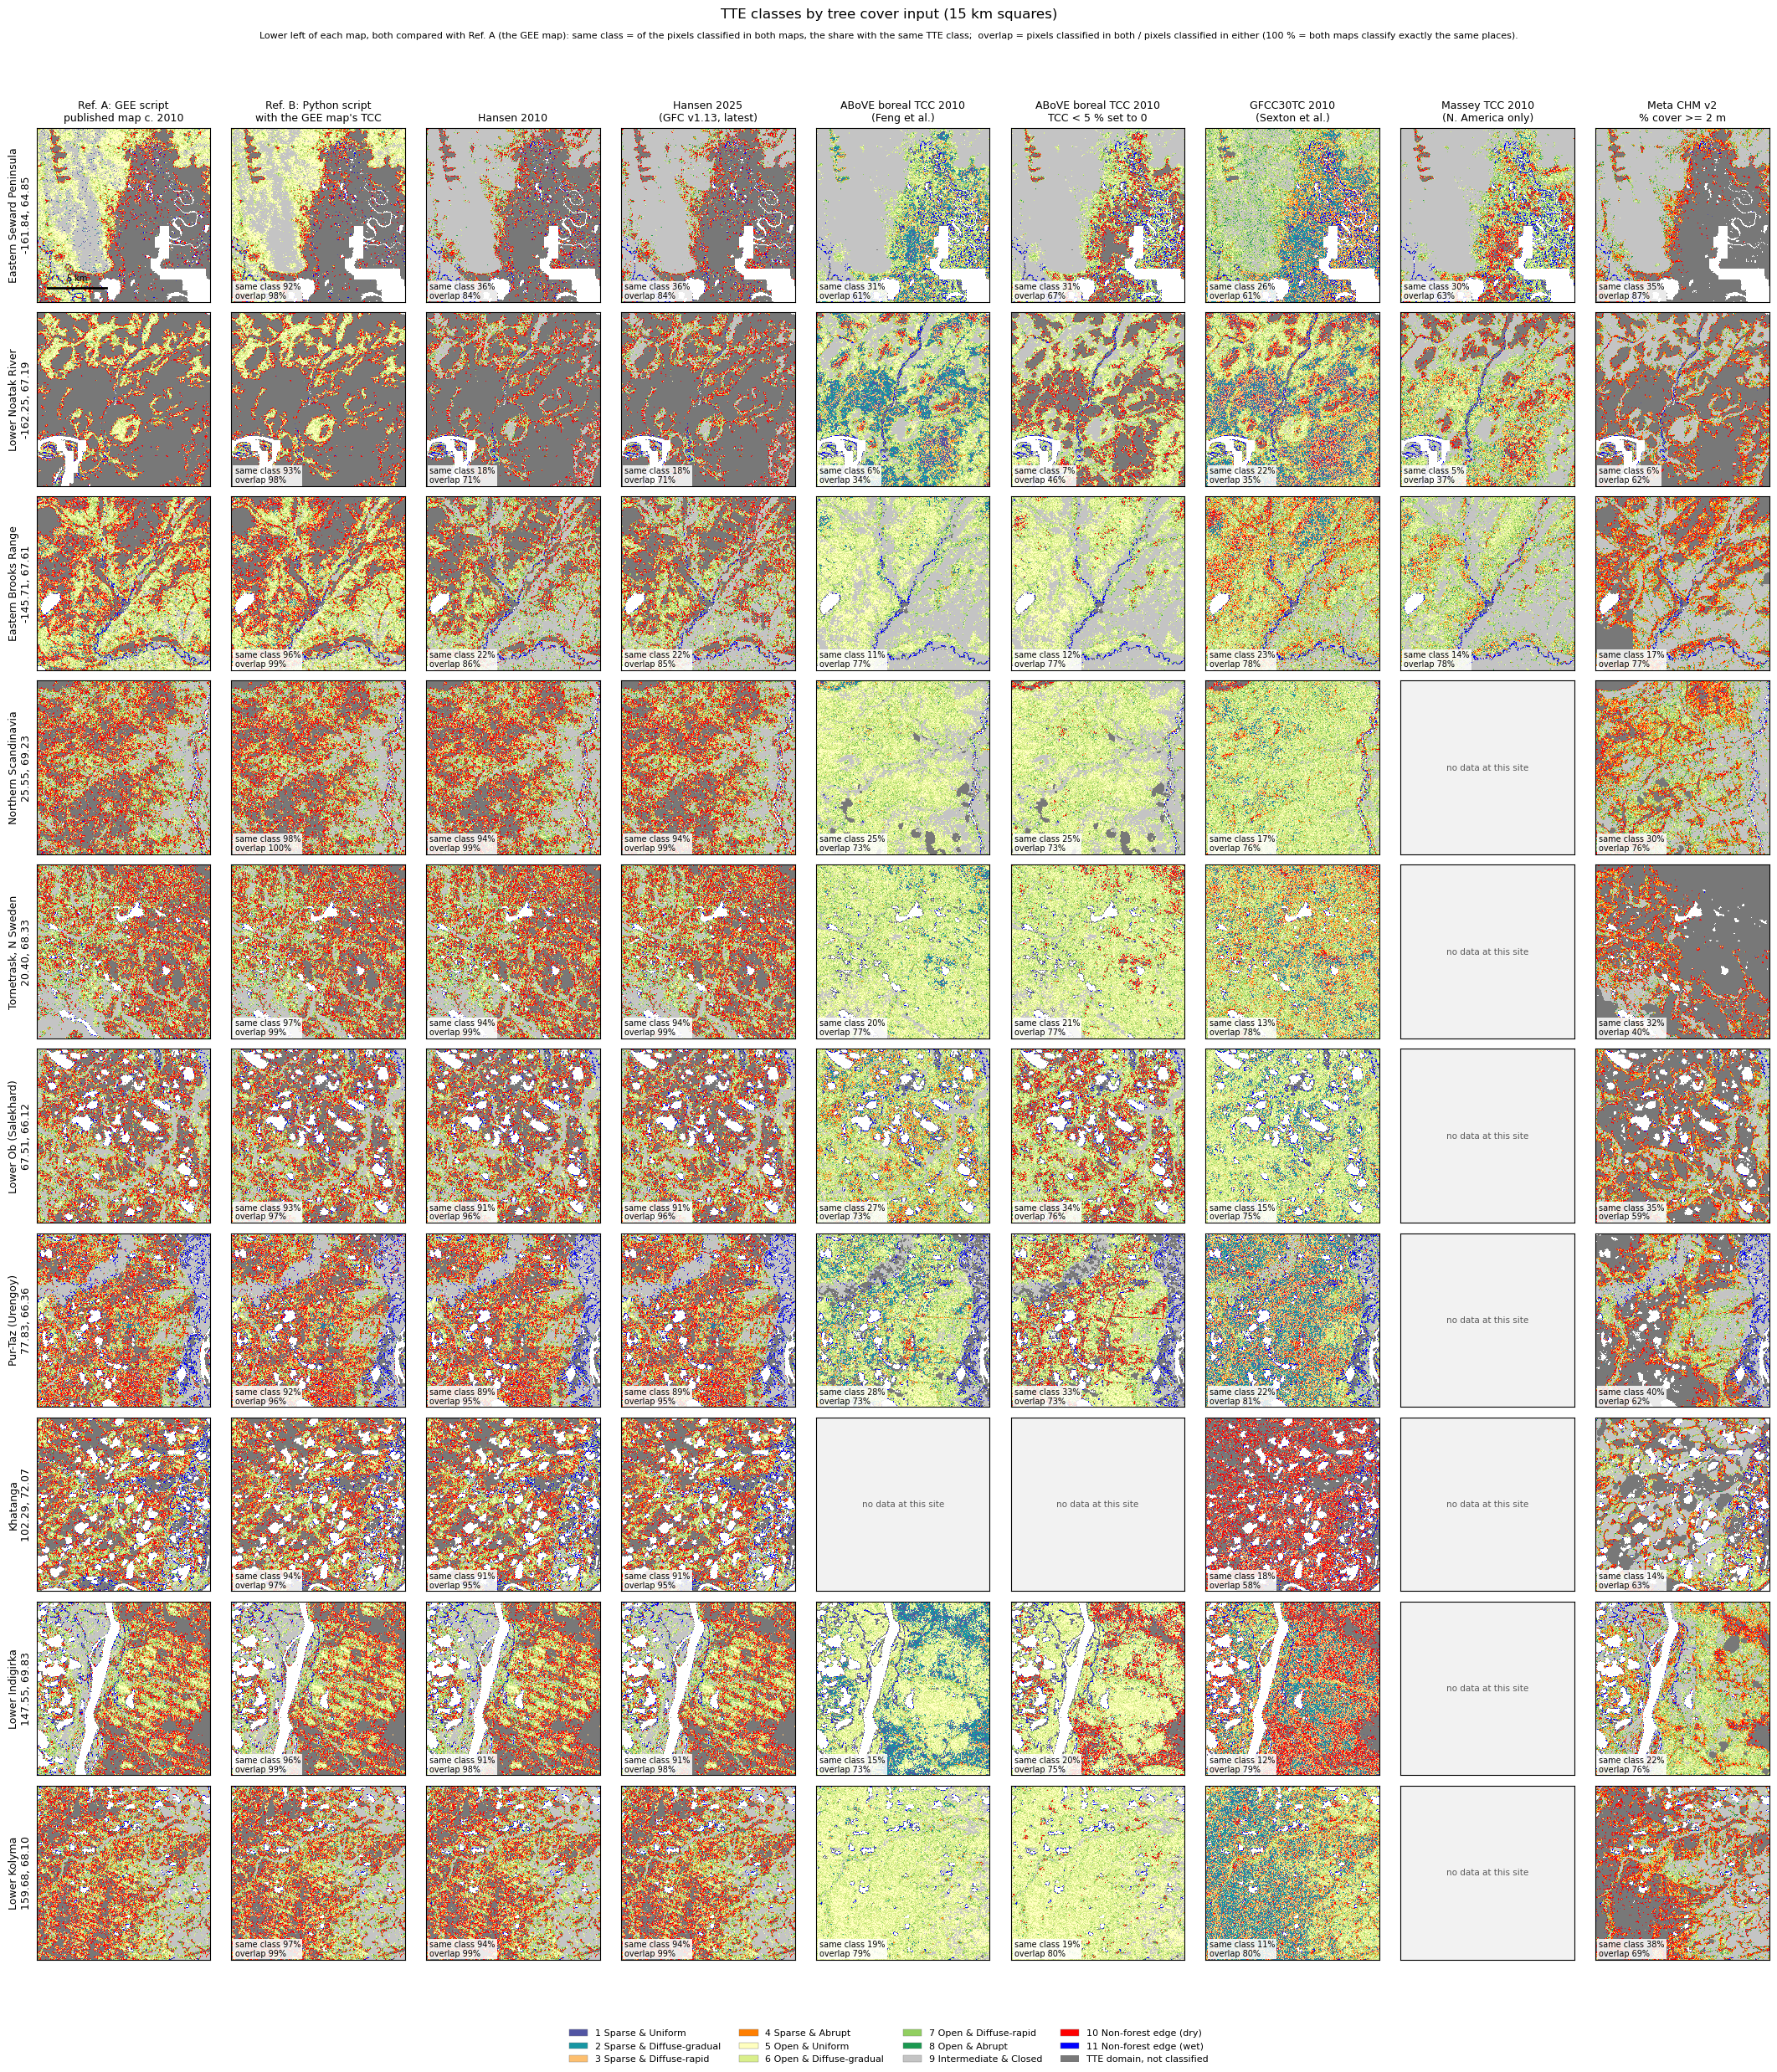

In [7]:
fig = tc.plot_matrix(DISP, SITES, COLUMNS, LABELS, SIZE_KM, status=STATUS, agree=AGREE, kind='classes',
                     title=f'TTE classes by tree cover input ({SIZE_KM} km squares)')
plt.show()

## 5. Matrix: the tree cover each column was run with

0-50 %, GEE TCC palette, inside the TTE domain. The reference column is the GEE map's `tcc` band
(domain pixels the map left unclassified are TCC 0).

/home/jovyan/code/tte/lib/tte_compare.py:362: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 1.15 / H, 1, 1 - top / H))


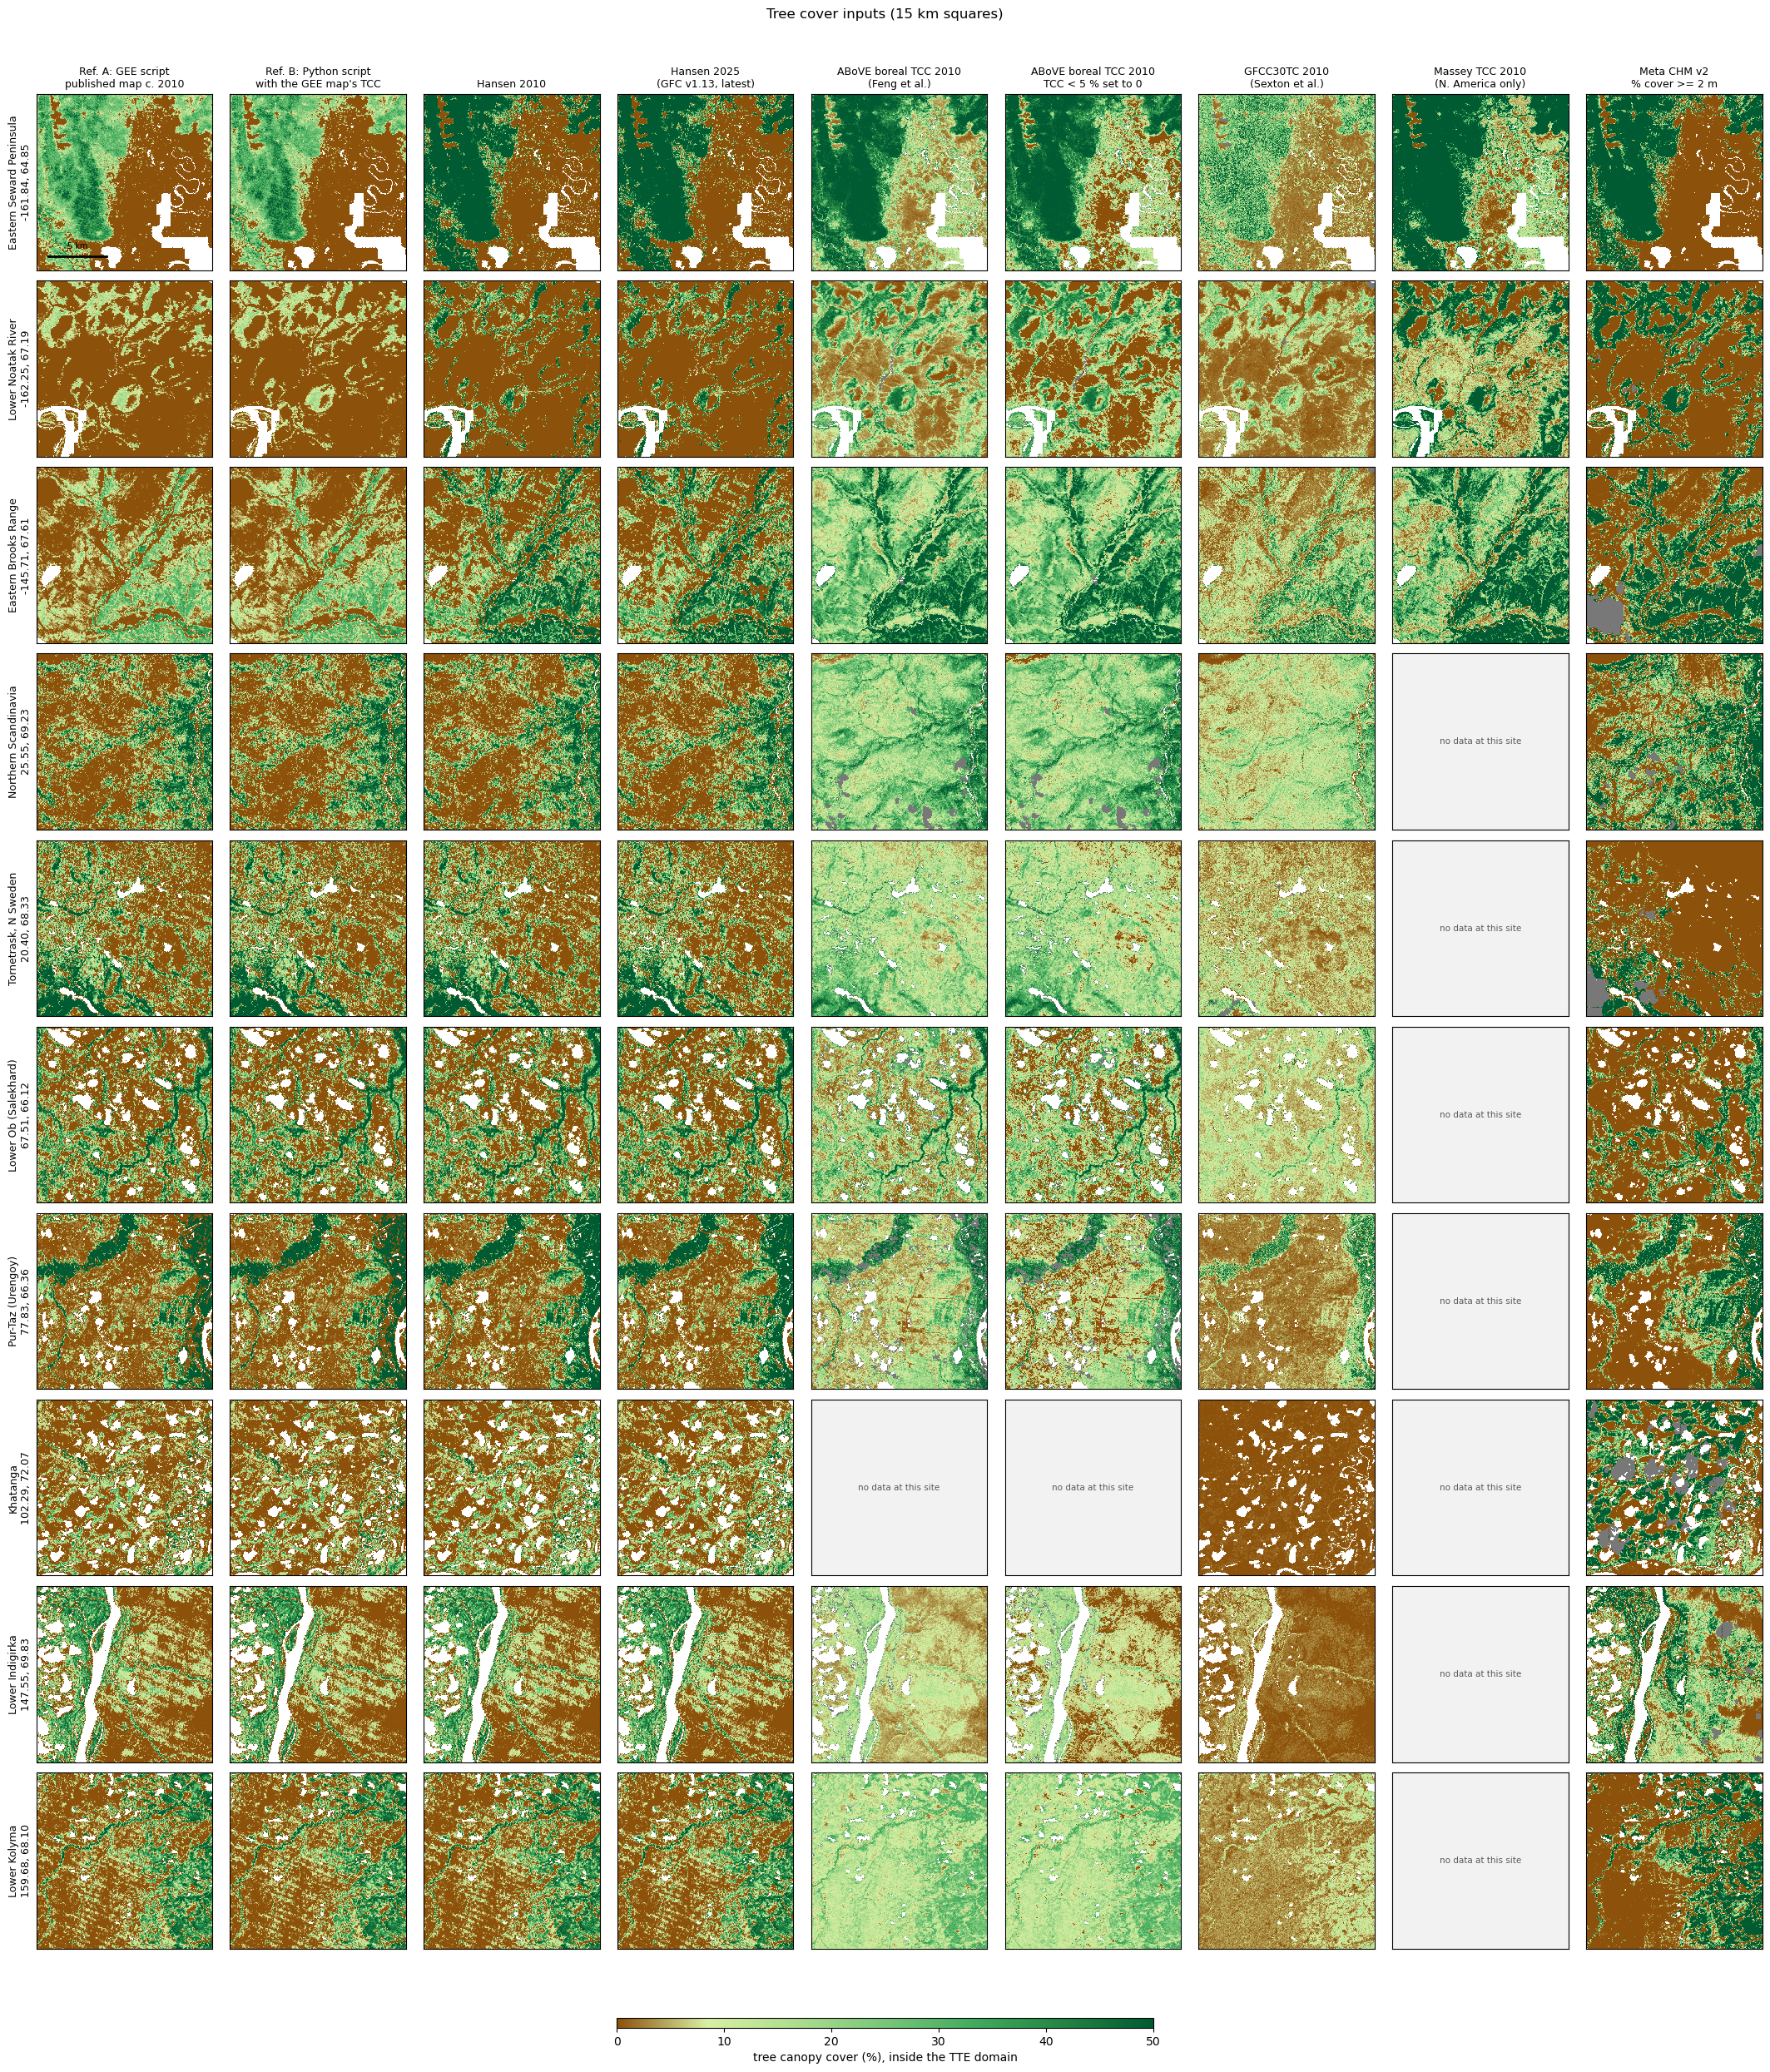

In [8]:
fig = tc.plot_matrix(DISP, SITES, COLUMNS, LABELS, SIZE_KM, status=STATUS, kind='tcc',
                     title=f'Tree cover inputs ({SIZE_KM} km squares)')
plt.show()

## 6. Class composition

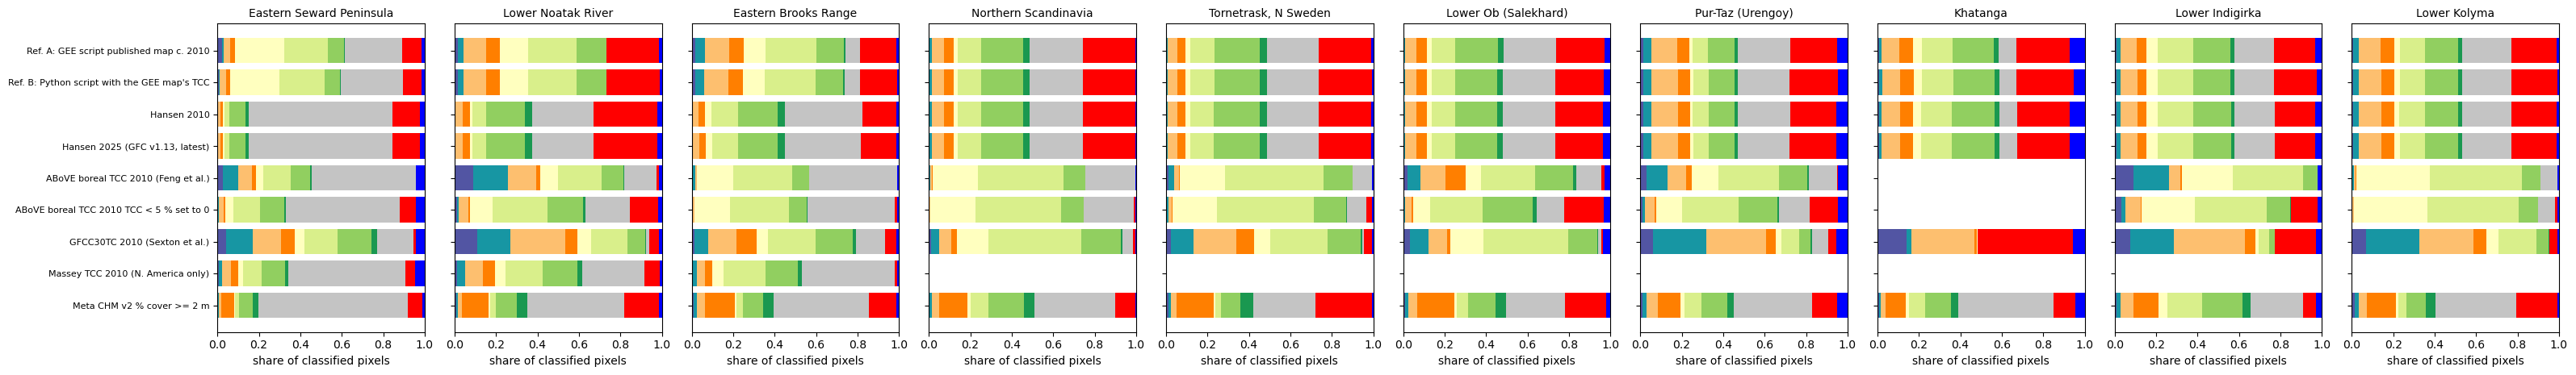

In [9]:
fig = tc.plot_composition(DISP, SITES, COLUMNS, LABELS)
plt.show()

## 7. Status of each run

In [10]:
pd.Series({f'{s} | {k}': v for (s, k), v in STATUS.items()}, name='status').to_frame()

,status
Eastern Seward Peninsula | gee_tcc,done
Eastern Seward Peninsula | hansen2010,done
Eastern Seward Peninsula | hansen2025,done
Eastern Seward Peninsula | above2010,done
Eastern Seward Peninsula | above2010_floor5,done
...,...
Lower Kolyma | above2010,done
Lower Kolyma | above2010_floor5,done
Lower Kolyma | gfcc2010,done
Lower Kolyma | meta_chm2m,done
